In [11]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import peak_signal_noise_ratio as psnr
from skimage.metrics import structural_similarity as ssim
from skimage.feature import hog
from skimage import exposure
from ultralytics import YOLO

print("Libraries imported successfully!")

Libraries imported successfully!


Importing libraries

Restored Gaussian -> PSNR: 26.42 dB | SSIM: 0.6241


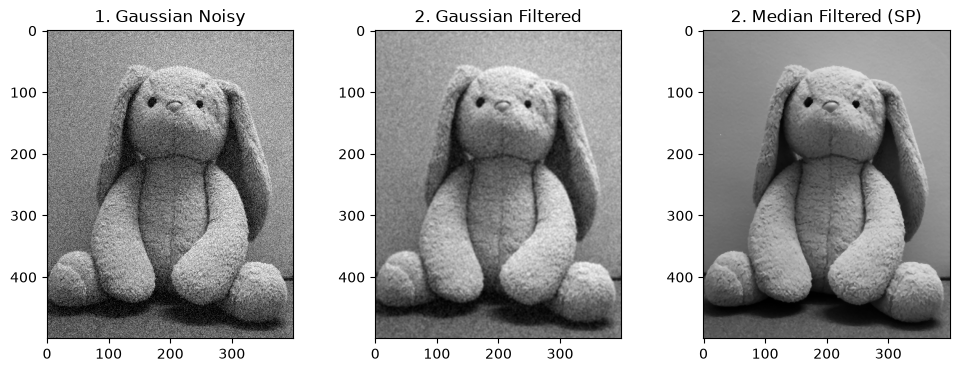

In [12]:
# Load original clean image
img_color = cv2.imread("original_photo.jpeg")
if img_color is None:
    raise FileNotFoundError("original_photo.jpeg not found!")
img_color = cv2.resize(img_color, (400, 500))
img_gray = cv2.cvtColor(img_color, cv2.COLOR_BGR2GRAY)

# 1. Add Gaussian Noise & Salt-and-Pepper Noise
gauss = np.random.normal(0, 25, img_gray.shape)
noisy_gaussian = np.clip(img_gray.astype(np.float32) + gauss, 0, 255).astype(np.uint8)

noisy_sp = img_gray.copy()
sp_prob = 0.05
num_salt = np.ceil(sp_prob * img_gray.size * 0.5)
noisy_sp[tuple([np.random.randint(0, i - 1, int(num_salt)) for i in img_gray.shape])] = 255
num_pepper = np.ceil(sp_prob * img_gray.size * 0.5)
noisy_sp[tuple([np.random.randint(0, i - 1, int(num_pepper)) for i in img_gray.shape])] = 0

# 2. Apply Filters (Gaussian for Gaussian noise, Median for Salt-and-Pepper)
restored_gaussian = cv2.GaussianBlur(noisy_gaussian, (5, 5), 0)
restored_median = cv2.medianBlur(noisy_sp, 3)

# 3 & 4. Calculate PSNR and SSIM
p_val = psnr(img_gray, restored_gaussian)
s_val = ssim(img_gray, restored_gaussian)
print(f"Restored Gaussian -> PSNR: {p_val:.2f} dB | SSIM: {s_val:.4f}")

# Display Restoration Outputs
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1), plt.imshow(noisy_gaussian, cmap='gray'), plt.title('1. Gaussian Noisy')
plt.subplot(1, 3, 2), plt.imshow(restored_gaussian, cmap='gray'), plt.title('2. Gaussian Filtered')
plt.subplot(1, 3, 3), plt.imshow(restored_median, cmap='gray'), plt.title('2. Median Filtered (SP)')
plt.show()

A. Image Restoration 

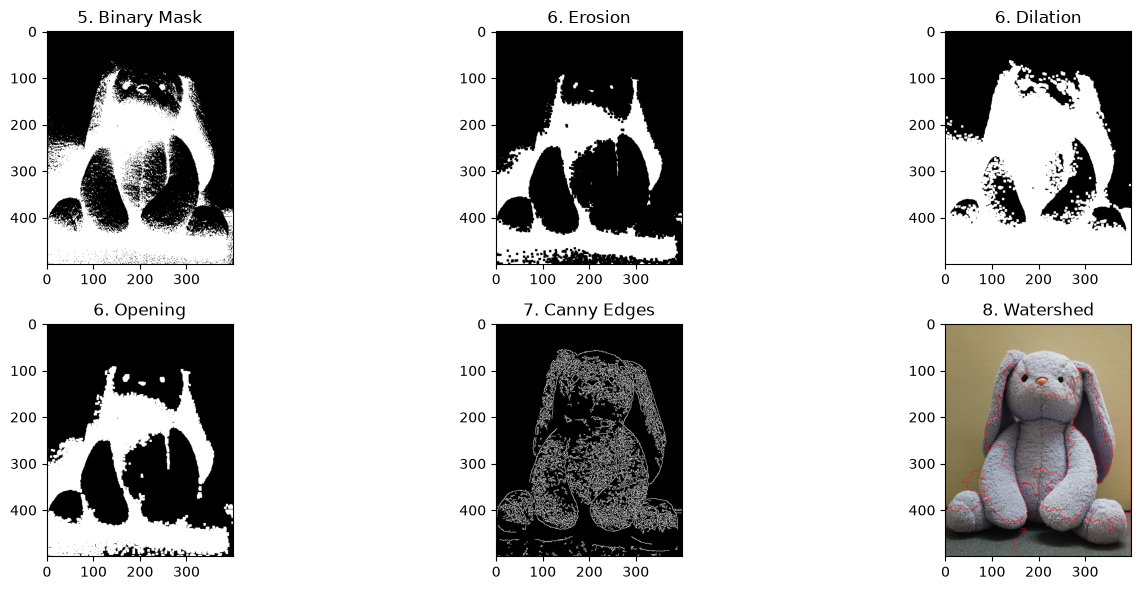

In [13]:
# 5. Thresholding to Binary Image
_, binary = cv2.threshold(img_gray, 120, 255, cv2.THRESH_BINARY_INV)

# 6. Apply Erosion, Dilation, Opening, Closing
kernel = np.ones((5, 5), np.uint8)
erosion = cv2.erode(binary, kernel, iterations=1)
dilation = cv2.dilate(binary, kernel, iterations=1)
opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel)
closing = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel)

# 7. Apply Canny Edge Detection
edges = cv2.Canny(img_gray, 100, 200)

# 8. Watershed Segmentation (for touching objects)
ret, thresh_ws = cv2.threshold(img_gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
sure_bg = cv2.dilate(thresh_ws, kernel, iterations=3)
dist_transform = cv2.distanceTransform(thresh_ws, cv2.DIST_L2, 5)
_, sure_fg = cv2.threshold(dist_transform, 0.5 * dist_transform.max(), 255, 0)
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)
_, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0
watershed_result = img_color.copy()
cv2.watershed(watershed_result, markers)
watershed_result[markers == -1] = [0, 0, 255]

# Display Morphological and Segmentation Outputs
plt.figure(figsize=(15, 6))
plt.subplot(2, 3, 1), plt.imshow(binary, cmap='gray'), plt.title('5. Binary Mask')
plt.subplot(2, 3, 2), plt.imshow(erosion, cmap='gray'), plt.title('6. Erosion')
plt.subplot(2, 3, 3), plt.imshow(dilation, cmap='gray'), plt.title('6. Dilation')
plt.subplot(2, 3, 4), plt.imshow(opening, cmap='gray'), plt.title('6. Opening')
plt.subplot(2, 3, 5), plt.imshow(edges, cmap='gray'), plt.title('7. Canny Edges')
plt.subplot(2, 3, 6), plt.imshow(cv2.cvtColor(watershed_result, cv2.COLOR_BGR2RGB)), plt.title('8. Watershed')
plt.tight_layout()
plt.show()

B. Morphological Processing and Segmentation

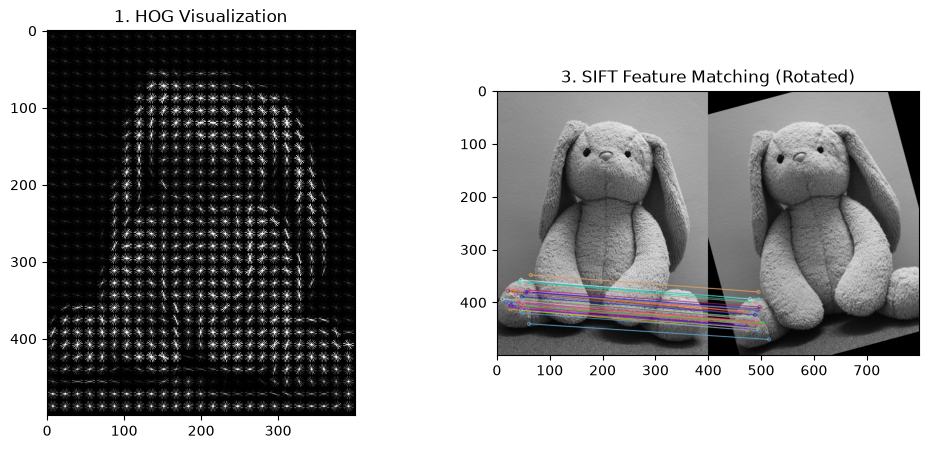

In [14]:
# Create second photo (rotated variant for matching evaluation)
matrix = cv2.getRotationMatrix2D((img_gray.shape[1]/2, img_gray.shape[0]/2), 15, 1.0)
img2_match = cv2.warpAffine(img_gray, matrix, (img_gray.shape[1], img_gray.shape[0]))

# 1. HOG Feature Extraction and Visualization
fd, hog_image = hog(img_gray, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), visualize=True, channel_axis=None)
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

# 2 & 3. SIFT Detection, Descriptors, and Matching
sift = cv2.SIFT_create()
kp1, des1 = sift.detectAndCompute(img_gray, None)
kp2, des2 = sift.detectAndCompute(img2_match, None)

bf = cv2.BFMatcher()
matches = bf.knnMatch(des1, des2, k=2)
good_matches = [m for m, n in matches if m.distance < 0.75 * n.distance]
match_img = cv2.drawMatches(img_gray, kp1, img2_match, kp2, good_matches[:40], None, flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

# Display Unit 4 Results
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1), plt.imshow(hog_image_rescaled, cmap='gray'), plt.title('1. HOG Visualization')
plt.subplot(1, 2, 2), plt.imshow(cv2.cvtColor(match_img, cv2.COLOR_BGR2RGB)), plt.title('3. SIFT Feature Matching (Rotated)')
plt.show()

Task 2: Feature Extraction and Image Matching 


0: 384x640 (no detections), 79.6ms
Speed: 7.2ms preprocess, 79.6ms inference, 3.2ms postprocess per image at shape (1, 3, 384, 640)


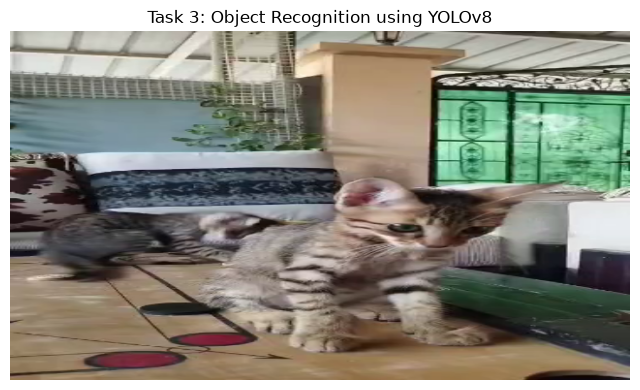

In [16]:
cap = cv2.VideoCapture("video.mp4")
success, frame1 = cap.read()
cap.release()

if success:
    frame1 = cv2.resize(frame1, (640, 360))
    
    # Run Pretrained YOLOv8 Object Detection
    model = YOLO('yolov8n.pt')
    results = model(frame1)
    yolo_annotated = results[0].plot()

    # Display Task 3 Results
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(yolo_annotated, cv2.COLOR_BGR2RGB))
    plt.title('Task 3: Object Recognition using YOLOv8')
    plt.axis('off')
    plt.show()
else:
    print("Error reading video.mp4 for Task 3")

Task 3: Object Recognition Using Viola–Jones and YOLO

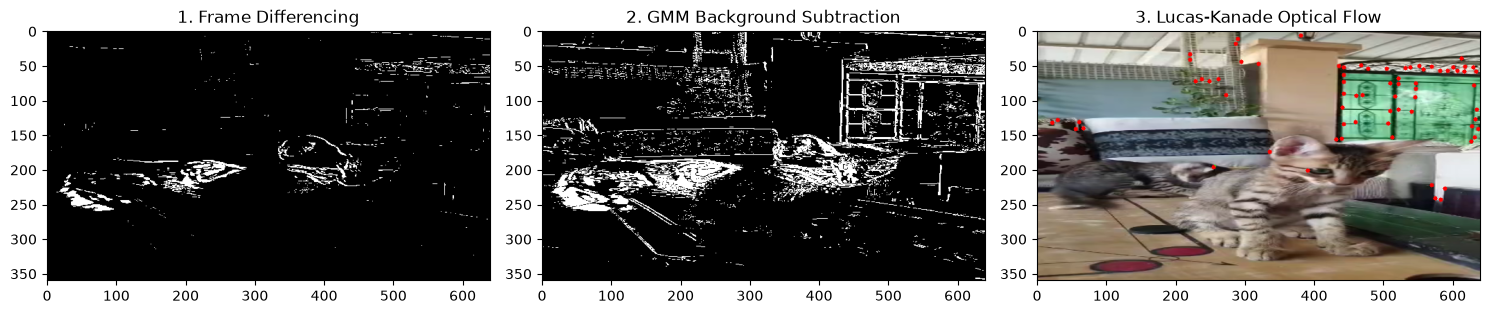

In [17]:
cap = cv2.VideoCapture("video.mp4")
success, frame1 = cap.read()
success, frame2 = cap.read()
cap.release()

if success:
    # Resize frames for consistent processing
    frame1 = cv2.resize(frame1, (640, 360))
    frame2 = cv2.resize(frame2, (640, 360))
    
    gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
    gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)
    
    # 1 & 2. Frame Differencing
    diff = cv2.absdiff(gray1, gray2)
    _, diff_thresh = cv2.threshold(diff, 25, 255, cv2.THRESH_BINARY)
    
    # 3. GMM-based Background Subtraction (MOG2)
    backSub = cv2.createBackgroundSubtractorMOG2()
    _ = backSub.apply(frame1)
    gmm_mask = backSub.apply(frame2)
    
    # 4. Lucas–Kanade Optical Flow
    feature_params = dict(maxCorners=100, qualityLevel=0.3, minDistance=7, blockSize=7)
    p0 = cv2.goodFeaturesToTrack(gray1, mask=None, **feature_params)
    
    lk_params = dict(winSize=(15, 15), maxLevel=2,
                     criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03))
    
    flow_frame = frame2.copy()
    if p0 is not None:
        p1, st, err = cv2.calcOpticalFlowPyrLK(gray1, gray2, p0, None, **lk_params)
        good_new = p1[st == 1]
        good_old = p0[st == 1]
        
        for new, old in zip(good_new, good_old):
            a, b = map(int, new.ravel())
            c, d = map(int, old.ravel())
            cv2.line(flow_frame, (a, b), (c, d), (0, 255, 0), 2)
            cv2.circle(flow_frame, (a, b), 3, (0, 0, 255), -1)

    # 5 & 6. Display Foreground Masks and Motion Visualizations
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1), plt.imshow(diff_thresh, cmap='gray'), plt.title('1. Frame Differencing')
    plt.subplot(1, 3, 2), plt.imshow(gmm_mask, cmap='gray'), plt.title('2. GMM Background Subtraction')
    plt.subplot(1, 3, 3), plt.imshow(cv2.cvtColor(flow_frame, cv2.COLOR_BGR2RGB)), plt.title('3. Lucas-Kanade Optical Flow')
    plt.tight_layout()
    plt.show()
else:
    print("Error: Could not read video.mp4 for motion estimation!")

Task 4: Video Motion Estimation 